# 01 – Khám phá dữ liệu (EDA)

Ba nguồn: **A** ViSD4SA, **B** Shopee CSV, **Aug** JSONL không dấu. Notebook này chỉ đọc file gốc, không sửa gì.

## 1. ViSD4SA: xem cách gán nhãn theo cụm

In [1]:
import json

with open("../ViSD4SA/train.jsonl", encoding="utf-8") as f:
    for i, line in enumerate(f):
        if i == 10:
            break
        row = json.loads(line)
        text = row["text"]
        print(f"--- Review {i} ---")
        print(text)
        for start, end, label in row["labels"]:
            print(f"  [{label}] -> {text[start:end]!r}")
        print()

--- Review 0 ---
Pin Sài tầm 50h cho pin 100/100. Camera ổn ... tất cả đều OK ... nhân viên thế giới di động trần văn thời cà mau nhiệt tình và vui vẻ ...chúc các ae sức khỏe tốt và phục ok hoài nha....
  [BATTERY#POSITIVE] -> 'Pin Sài tầm 50h cho pin 100/100'
  [CAMERA#POSITIVE] -> 'Camera ổn'
  [GENERAL#POSITIVE] -> 'tất cả đều OK'
  [SER&ACC#POSITIVE] -> 'nhân viên thế giới di động trần văn thời cà mau nhiệt tình và vui vẻ ...chúc các ae sức khỏe tốt và phục ok hoài nha'

--- Review 1 ---
Lag và hao pin là cái tóm tắt về máy. Sam làm tệ quá, không bằng mấy con tàu cùng phân khúc
  [PERFORMANCE#NEGATIVE] -> 'Lag'
  [BATTERY#NEGATIVE] -> 'hao pin'
  [GENERAL#NEGATIVE] -> 'Sam làm tệ quá, không bằng mấy con tàu cùng phân khúc'

--- Review 2 ---
Tất cả đều ổn ngoại trừ lúc máy nóng lên thì pin tụt nhanh hơn tụt quần haizz. Cam chụp cũng gọi là tầm trung. Nếu dùng lướt web bình thường thì có thể dùng được cả ngày
  [CAMERA#NEUTRAL] -> 'Cam chụp cũng gọi là tầm trun

In [2]:
import json, re, unicodedata, collections
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score

pd.set_option("display.max_colwidth", 120)

def read_visd(split):
    return [json.loads(l) for l in open(f"../ViSD4SA/{split}.jsonl", encoding="utf-8")]

visd_raw = {sp: read_visd(sp) for sp in ["train", "dev", "test"]}
for sp, rows in visd_raw.items():
    n_spans = sum(len(r["labels"]) for r in rows)
    print(f"{sp:5s}: {len(rows):5d} review, trung bình {n_spans/len(rows):.2f} cụm/review")

train:  7785 review, trung bình 3.18 cụm/review
dev  :  1112 review, trung bình 3.22 cụm/review
test :  2225 review, trung bình 3.17 cụm/review


In [3]:
# Số cụm theo khía cạnh và theo cảm xúc (tập train)
asp = collections.Counter(t.split("#")[0] for r in visd_raw["train"] for _, _, t in r["labels"])
pol = collections.Counter(t.split("#")[1] for r in visd_raw["train"] for _, _, t in r["labels"])
display(pd.Series(asp).sort_values(ascending=False).to_frame("số cụm"))
display(pd.Series(pol).to_frame("số cụm"))

,số cụm
GENERAL,5637
PERFORMANCE,4799
BATTERY,3943
FEATURES,2788
CAMERA,2182
SER&ACC,1875
DESIGN,1497
PRICE,995
SCREEN,962
STORAGE,93


,số cụm
POSITIVE,15203
NEGATIVE,7999
NEUTRAL,1569


In [4]:
# Kiểm tra chất lượng: cụm có end vượt độ dài câu, câu chưa chuẩn NFC, review không có cụm nào
all_rows = [r for rows in visd_raw.values() for r in rows]
bad_end = [(r["text"], e) for r in all_rows for _, e, _ in r["labels"] if e > len(r["text"])]
not_nfc = sum(unicodedata.normalize("NFC", r["text"]) != r["text"] for r in all_rows)
no_label = sum(len(r["labels"]) == 0 for r in all_rows)
print("Cụm có end > len(text):", len(bad_end), "| vượt nhiều nhất:", max(e - len(t) for t, e in bad_end))
print("Câu chưa chuẩn NFC:", not_nfc)
print("Review không có cụm nào:", no_label)
mixed = sum(len({t.split('#')[1] for _, _, t in r["labels"]}) > 1 for r in all_rows)
print(f"Review có nhiều cảm xúc khác nhau: {mixed} ({mixed/len(all_rows):.0%})")

Cụm có end > len(text): 122 | vượt nhiều nhất: 25
Câu chưa chuẩn NFC: 331
Review không có cụm nào: 225
Review có nhiều cảm xúc khác nhau: 4302 (39%)


In [5]:
# Trùng lặp giữa các tập ViSD4SA
texts = {sp: set(r["text"] for r in rows) for sp, rows in visd_raw.items()}
print("train ∩ test:", len(texts["train"] & texts["test"]))
print("train ∩ dev :", len(texts["train"] & texts["dev"]))
print("dev ∩ test  :", len(texts["dev"] & texts["test"]))

train ∩ test: 2
train ∩ dev : 1
dev ∩ test  : 0


## 2. Shopee CSV (bộ B)

In [6]:
df = pd.read_csv("../data/final_train_dataset.csv").rename(
    columns={"prod": "product", "com": "text", "rat": "rating"})
df["text"] = df["text"].astype(str)
print(df.shape, "|", df["product"].nunique(), "sản phẩm")
print(df.rating.value_counts().sort_index())

(2843, 3) | 32 sản phẩm
rating
1.0     366
2.0     237
3.0     243
4.0     454
5.0    1543
Name: count, dtype: int64


In [7]:
# 10 sản phẩm nhiều review nhất
df.groupby("product").rating.agg(["size", "mean"]).sort_values("size", ascending=False).head(10)

,size,mean
product,,
Combo Tiết Kiệm: 6 Gói Khăn Ướt Bobby Care Không Hương 100 Miếng/Gói,518,4.988417
"Nước hoa nam cao cấp chính hãng Jile Guilty 50ml với hương thơm mạnh mẽ, nam tính, lịch lãm, quý phái.",299,4.986622
Sữa rửa mặt dưỡng trắng Hada Labo Perfect White Tranexamic Acid Cleanser 80g,185,4.994595
Đồng hồ điện tử nam nữ sport S07 kiểu dáng thời trang thể thao,117,4.034188
⚡KHĂN DÀY⚡Khăn lau xe chuyên dụng ô tô lau bếp lau kính Microfiber siêu thấm không bị sơ rối 2 lớp 88419,101,3.198020
Áo thun polo nữ thời trang GUMAC có cổ đẹp thiết kế trơn cơ bản ATC04011,79,3.113924
Quần đùi nam thể thao quần short hàng xuất cao cấp phong cách trẻ trung năng động T80,77,2.168831
Baseus Củ Sạc Bộ Cáp Nhanh PD 20W GaN 5 Sạc điện cho Không Nóng Máy An Toàn Ổn Định,74,3.067568
[ Hàng Sẵn ] Cây Xương Rồng Nhảy Múa Phát Ra Âm Thanh Vui Nhộn Cho Bé - 120 bài hát + có nhại tiếng,74,3.256757


count    2843.000000
mean       31.787197
std        32.925834
min         1.000000
25%        11.000000
50%        24.000000
75%        37.000000
max       351.000000
Name: n_words, dtype: float64


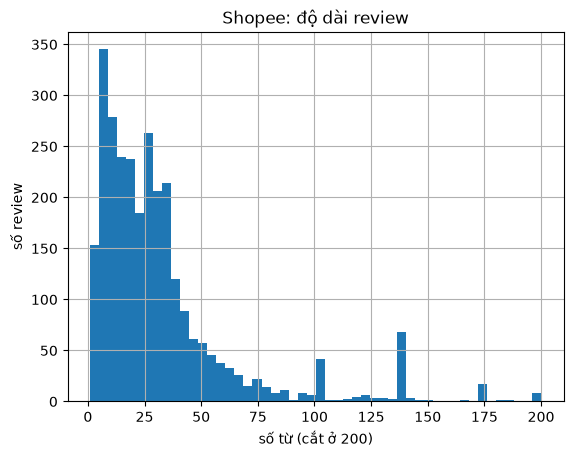

In [8]:
df["n_words"] = df.text.str.split().str.len()
print(df.n_words.describe())
ax = df.n_words.clip(upper=200).hist(bins=50)
ax.set_xlabel("số từ (cắt ở 200)"); ax.set_ylabel("số review"); ax.set_title("Shopee: độ dài review")
plt.show()

In [9]:
junk = df.text.str.match(r"^\s*Tổng quan\s*\n\s*\d")
print("Dòng rác giao diện 'Tổng quan…':", junk.sum())
print(df[junk].text.iloc[0][:300])
print()
print("Dòng trùng nguyên văn:", df.duplicated(subset=["text"]).sum())
print("Review < 2 từ:", (df.n_words < 2).sum())

Dòng rác giao diện 'Tổng quan…': 120
Tổng quan
4.9
(3034 đánh giá)
2781
195
18
7
33
Trợ lý AI tổng hợp
từ các đánh giá mới nhất
Về sản phẩm: (68 tích cực, 1 tiêu cực)
Hầu hết người mua đánh giá tích cực về chất lượng sản phẩm, đặc biệt là khăn mềm mịn, không mùi và an toàn cho bé.
Một số người mua nhận xét sản phẩm đúng như mô tả, đóng

Dòng trùng nguyên văn: 282
Review < 2 từ: 10


In [10]:
# Tự kiểm tra: nếu đoán 'pos' cho mọi câu thì sao? (nhãn yếu từ sao, sau khi bỏ rác)
weak = df[~junk].rating.map({1: "neg", 2: "neg", 3: "neu", 4: "pos", 5: "pos"})
always_pos = ["pos"] * len(weak)
print(weak.value_counts(normalize=True).round(3))
print(f"Accuracy = {accuracy_score(weak, always_pos):.3f}, F1-macro = {f1_score(weak, always_pos, average='macro'):.3f}")

rating
pos    0.689
neg    0.221
neu    0.089
Name: proportion, dtype: float64
Accuracy = 0.689, F1-macro = 0.272


In [11]:
# Review 4–5 sao nhưng nội dung có ý chê -> vì sao số sao chỉ là nhãn YẾU
NEG_HINT = r"thất vọng|tệ|kém|không như|không giống|hơi mỏng|lỗi|hỏng|chậm|nhưng mà|tuy nhiên|không hài lòng"
cand = df[(df.rating >= 4) & ~junk & df.text.str.contains(NEG_HINT, case=False)]
print(len(cand), "ứng viên — tự đọc và chọn 3 ví dụ cho báo cáo:")
cand.sample(10, random_state=42)[["rating", "text"]]

59 ứng viên — tự đọc và chọn 3 ví dụ cho báo cáo:


,rating,text
137,4.0,"Chất lượng sản phẩm:cx dc\nĐúng với mô tả:giống hình\nnón đẹp nhưng bị lỗi ở phần mũ nón , giao nhanh ms đặt hqua hn..."
428,4.0,Đúng với mô tả:Đúng với mô tả\nNói chung mua hàng của coolmate cũng nhiều rồi chất lượng thì cũng ok tin tưởng cho n...
1406,4.0,"Đúng với mô tả:Như hình\nMàu sắc:trắng và đen\nChất liệu:nhựa\nHàng chất lượng á, sản phẩm sử dụng giờ chạy vẫn oke,..."
720,4.0,Nhận máy nhanh đúng ngày giao hàng. Máy đẹp không lỗi nhỏ.
1839,5.0,Chất lượng sản phẩm:tốt\nTính năng nổi bật:giúp có nhiều ổ cắm hơn\n\nhàng khá tốt và đẹp hoạt động bình thường khôn...
2393,5.0,"mình mua tặng nên chưa review được mùi, tuy nhiên gói hàng cẩn thận, giao hàng nhanh khủng khiếp, mới đặt buổi tối m..."
2666,5.0,"Sữa rửa mặt giá rẻ nhưng mà chất lượng thật sự, mua 3 lần rồi ọ nhưng mà vẫn ưnggg. Vừa đặt hôm qua mà hôm nay đã có..."
1038,4.0,"Màu sắc:da\nDán xoài hơi mỏng và k có đệm làm cho ngực mjk k có tạo khe dk, bàn tay thì có đệm dày nhìn có from và c..."
1868,5.0,Nhận hàng đc tặng kèm hộp.mặt hàng ok tuy nhiên ship hơi lâu minh đặt gần 2 tuần mới nhận đc.
711,4.0,Đúng với mô tả:ok\nTính năng nổi bật:ok\nChất lượng sản phẩm:bị xước cạnh\nMắc xương 🥲 ở ngoài 2 dấu cấn khá rõ chắc...


## 3. JSONL không dấu (bộ Aug)

In [12]:
j = pd.read_json("../data/aug_unaccented_reviews.jsonl", lines=True)
j["n_words"] = j.review.str.split().str.len()
print(j.shape)
display(pd.crosstab(j.rating, j.label, margins=True))
print(j.n_words.describe())
print("Trùng nguyên văn:", j.duplicated(subset=["review"]).sum())
print("Dòng có *, tab hoặc dấu \":", j.review.str.contains(r'[*\t"]', regex=True).sum())

(1347, 5)


label,negative,positive,All
rating,,,
1,418,4,422
2,135,2,137
3,118,13,131
4,4,25,29
5,1,627,628
All,676,671,1347


count    1347.000000
mean       70.531552
std        40.634944
min         6.000000
25%        40.000000
50%        64.000000
75%        86.000000
max       444.000000
Name: n_words, dtype: float64
Trùng nguyên văn: 0
Dòng có *, tab hoặc dấu ": 55


## 4. Bảng tổng hợp 3 nguồn

In [13]:
summary = pd.DataFrame([
    {"nguồn": "A: ViSD4SA", "số dòng": sum(len(v) for v in visd_raw.values()),
     "nhãn": "cụm từ, 10 khía cạnh × 3 cảm xúc", "miền": "điện thoại"},
    {"nguồn": "B: Shopee CSV", "số dòng": len(df), "nhãn": "sao 1–5 (nhãn yếu)", "miền": f"{df['product'].nunique()} sản phẩm đa ngành"},
    {"nguồn": "Aug: JSONL", "số dòng": len(j), "nhãn": "positive/negative + sao", "miền": "đa ngành, không dấu"},
])
summary

,nguồn,số dòng,nhãn,miền
0,A: ViSD4SA,11122,"cụm từ, 10 khía cạnh × 3 cảm xúc",điện thoại
1,B: Shopee CSV,2843,sao 1–5 (nhãn yếu),32 sản phẩm đa ngành
2,Aug: JSONL,1347,positive/negative + sao,"đa ngành, không dấu"


## 5. Bảng sản phẩm → ngành hàng

Ngành hàng được gán sơ bộ theo từ khóa trong tên sản phẩm bằng danh sách RULES. Đây là biến phân nhóm để EDA và phân tích theo miền, không phải đầu vào nhãn cảm xúc. Cần người thực hiện xác nhận bảng ánh xạ trước khi suy rộng kết luận theo ngành; chưa có bằng chứng phỏng vấn hoặc phân loại nghiệp vụ độc lập.


In [14]:
RULES = [  # (từ khóa trong tên sản phẩm, ngành hàng) — xét theo thứ tự, khớp cái đầu tiên
    ("Bobby", "Mẹ & bé"), ("Xương Rồng", "Mẹ & bé"),
    ("Nước hoa", "Mỹ phẩm"), ("Hada Labo", "Mỹ phẩm"), ("La Roche-Posay", "Mỹ phẩm"),
    ("Sách", "Sách – văn phòng phẩm"), ("Truyện", "Sách – văn phòng phẩm"), ("Bút gel", "Sách – văn phòng phẩm"),
    ("Bánh tráng", "Đồ ăn"),
    ("iPhone", "Điện tử"), ("Củ Sạc", "Điện tử"), ("USB", "Điện tử"), ("Chuột", "Điện tử"),
    ("Thẻ SD", "Điện tử"), ("Laptop", "Điện tử"),
    ("Mũ Bảo Hiểm", "Phụ kiện xe"), ("Mũ bảo hiểm", "Phụ kiện xe"), ("Kính Chống Bụi", "Phụ kiện xe"),
    ("lau xe", "Phụ kiện xe"),
    ("bóng đá", "Thể thao"), ("Quả bóng", "Thể thao"), ("Tập Gym", "Thể thao"),
    ("Áo thể thao", "Thể thao"), ("Quần đùi", "Thể thao"),
    ("Bình Giữ Nhiệt", "Nhà cửa – đời sống"),
    ("Đồng hồ", "Thời trang"), ("Áo", "Thời trang"), ("ÁO", "Thời trang"), ("Balo", "Thời trang"),
    ("Dép", "Thời trang"), ("Thắt lưng", "Thời trang"),
]

def category(name):
    name = unicodedata.normalize("NFC", name)   # 2 tên sản phẩm đang ở dạng NFD
    return next((cat for kw, cat in RULES if kw in name), None)

cat = pd.DataFrame({"product": sorted(df["product"].unique())})
cat["category"] = cat["product"].map(category)
assert cat.category.notna().all(), cat[cat.category.isna()]
import os
os.makedirs("../data/processed", exist_ok=True)
cat.to_csv("../data/processed/product_category.csv", index=False, encoding="utf-8-sig")
display(cat.category.value_counts())
cat

category
Thời trang               6
Điện tử                  6
Thể thao                 5
Phụ kiện xe              4
Sách – văn phòng phẩm    3
Mẹ & bé                  3
Mỹ phẩm                  3
Đồ ăn                    1
Nhà cửa – đời sống       1
Name: count, dtype: int64

,product,category
0,(Kèm 1 sốt tắc) COMBO Ú Ù (Bánh tráng + Tóp mỡ + túi Bơ + Ruốc hành phi),Đồ ăn
1,ÁO BRA DÁN NÂNG NGỰC SILICON CÀI TRƯỚC KHÔNG GỌNG HÌNH BÀN TAY P29 BC_CHIC LINGERIE,Thời trang
2,Balo CAMELIA BRAND® Global Backpack,Thời trang
3,Baseus Củ Sạc Bộ Cáp Nhanh PD 20W GaN 5 Sạc điện cho Không Nóng Máy An Toàn Ổn Định,Điện tử
4,Bình Giữ Nhiệt Nóng Lạnh 1000ml Chất Liệu Inox 304 Cao Cấp - Bảo Quản Nhiệt Độ Tốt - Chất Liệu An Toàn,Nhà cửa – đời sống
5,Bút gel vỏ trong suốt CÔ.THỦY ngòi 0.5mm dành cho học sinh BG03,Sách – văn phòng phẩm
6,Bộ chia trung tâm USB với bộ chia công tắc riêng lẻ với công tắc riêng lẻ Bộ chuyển đổi USB Hub Ổ cắm đa cổng được h...,Điện tử
7,Combo Tiết Kiệm: 6 Gói Khăn Ướt Bobby Care Không Hương 100 Miếng/Gói,Mẹ & bé
8,"Dép DO Dán Nam Nữ Thời Trang - Đế Cao Su Đúc 3cm, Phong Cách Linh Hoạt, HotTrend, Êm Ái",Thời trang
9,Kem dưỡng giảm mụn nhanh 8 giờ La Roche-Posay Effaclar Duo+ M 7.5ml,Mỹ phẩm
